# Bets e endividamento das famílias — análise com dados públicos

**Pergunta:** as bets são a maior causa do endividamento das famílias brasileiras?

**Estratégia (três testes simples):**
1. **Contábil** — quanto da *variação* da dívida das famílias as bets poderiam explicar, mesmo no pior caso (toda perda líquida financiada com crédito).
2. **Composição** — quais modalidades de crédito puxaram o crescimento da dívida desde 2023.
3. **Econométrico** — o endividamento depois de 2023 se desvia do que juros, renda e desemprego já explicam?

**Fontes:** SGS/Banco Central (API pública), PNAD Contínua/IBGE via SGS, e números de mercado de apostas citados com fonte.

> ⚠️ Confira os códigos SGS na célula 2 em https://www3.bcb.gov.br/sgspub antes de usar o resultado — o notebook imprime o último valor de cada série para checagem.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
# Séries do SGS (verificar os códigos no portal SGS)
SERIES = {
    "endiv":       29037,  # Endividamento das famílias c/ SFN (% renda 12m)
    "endiv_exhab": 29038,  # Idem, exceto financiamento habitacional
    "comprom":     29034,  # Comprometimento de renda das famílias c/ SFN (%)
    "saldo_pf":    20541,  # Saldo da carteira de crédito PF - total (R$ milhões)
    "selic":       4189,   # Selic acumulada no mês, anualizada (% a.a.)
    "desocup":     24369,  # Taxa de desocupação - PNAD Contínua (%)
}

def sgs(codigo, inicio="01/01/2015"):
    url = f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados?formato=json&dataInicial={inicio}"
    s = pd.read_json(url)
    s["data"] = pd.to_datetime(s["data"], dayfirst=True)
    return s.set_index("data")["valor"].astype(float)

df = pd.DataFrame({nome: sgs(cod) for nome, cod in SERIES.items()}).resample("MS").last()
# Última data com dado em cada série (as de endividamento saem com ~2 meses de defasagem)
df.apply(lambda s: s.last_valid_index())

endiv         2026-07-01
endiv_exhab   2026-07-01
comprom       2026-07-01
saldo_pf      2026-08-01
selic         2026-10-01
desocup       2026-08-01
dtype: datetime64[ns]

## 1. Teste contábil

Os R$ 18–30 bi/mês citados na imprensa são **depósitos brutos** — a maior parte volta como prêmio. O que sai do bolso das famílias é a **receita bruta de jogo (GGR)**: depósitos menos prêmios.

Aqui se assume o pior caso para as bets: **100% da perda líquida financiada com dívida nova**. Se nem assim explicar a maior parte do aumento da dívida, elas não são a principal causa.

Preencha `GGR_ANUAL` com a fonte que preferir (SPA/Ministério da Fazenda, BC, consultorias). O valor padrão é a estimativa de R$ 37 bi/ano da Tendências/Peers para 2026.

Saldo PF mais recente: R$ 4.67 trilhões
Aumento em 12 meses:   R$ 442 bilhões
Teto da participação das bets no aumento: 8.4%


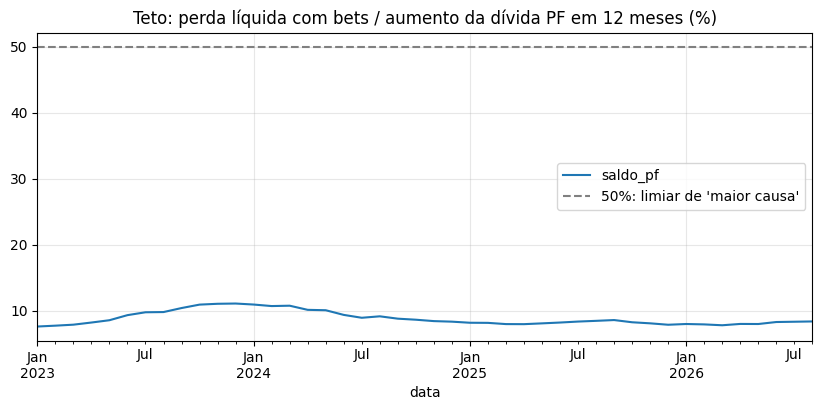

In [3]:
GGR_ANUAL = 37_000  # R$ milhões/ano — ajuste conforme a fonte

saldo = df["saldo_pf"].dropna()
var_12m = saldo.diff(12)               # aumento da dívida PF em 12 meses
participacao = 100 * GGR_ANUAL / var_12m

print(f"Saldo PF mais recente: R$ {saldo.iloc[-1]/1e6:.2f} trilhões")
print(f"Aumento em 12 meses:   R$ {var_12m.iloc[-1]/1e3:.0f} bilhões")
print(f"Teto da participação das bets no aumento: {participacao.iloc[-1]:.1f}%")

participacao["2023":].plot(title="Teto: perda líquida com bets / aumento da dívida PF em 12 meses (%)")
plt.axhline(50, ls="--", c="gray", label="50%: limiar de 'maior causa'")
plt.legend(); plt.show()

## 2. O que puxou o endividamento

Comparação de endividamento total e exceto habitação, comprometimento de renda e Selic. Se a dívida acompanha o ciclo de juros, o motor é o custo do crédito.

Para abrir por modalidade (cartão, consignado CLT, veículos, pessoal), acrescente os códigos de saldo por modalidade em `SERIES` — eles estão no SGS em *Crédito > Saldos > Pessoas físicas*.

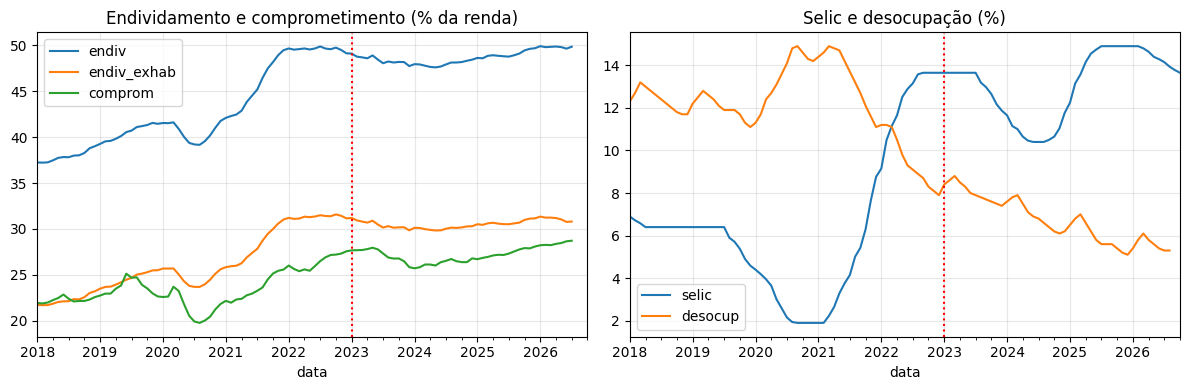

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[["endiv", "endiv_exhab", "comprom"]]["2018":].plot(ax=ax[0], title="Endividamento e comprometimento (% da renda)")
df[["selic", "desocup"]]["2018":].plot(ax=ax[1], title="Selic e desocupação (%)")
for a in ax: a.axvline("2023-01-01", c="red", ls=":", label="expansão das bets")
plt.tight_layout(); plt.show()

## 3. Teste econométrico

Modelo do endividamento (em variação) com juros, desemprego e crescimento do crédito defasados, mais uma dummy `pos_bets` a partir de 2023.

**Leitura honesta:** a dummy captura *tudo* que mudou depois de 2023 — bets, consignado CLT, Desenrola, ciclo de juros. Um coeficiente positivo **não** isola as bets; um coeficiente pequeno ou não significativo é evidência de que, no agregado, elas não dominam. Erros-padrão HAC (Newey-West) por causa da autocorrelação.

In [5]:
d = df.copy()
d["d_endiv"]    = d["endiv"].diff()
d["selic_l3"]   = d["selic"].shift(3)
d["desocup_l1"] = d["desocup"].shift(1)
d["cred_g12"]   = 100 * d["saldo_pf"].pct_change(12, fill_method=None)
d["pos_bets"]   = (d.index >= "2023-01-01").astype(int)
d = d["2016":].dropna()

modelo = smf.ols("d_endiv ~ selic_l3 + desocup_l1 + cred_g12 + pos_bets", data=d)
res = modelo.fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(res.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.2046      0.690     -0.297      0.767      -1.557       1.148
selic_l3      -0.0309      0.018     -1.720      0.085      -0.066       0.004
desocup_l1     0.0307      0.037      0.831      0.406      -0.042       0.103
cred_g12       0.0177      0.012      1.512      0.130      -0.005       0.041
pos_bets       0.1965      0.142      1.386      0.166      -0.081       0.474


In [6]:
# Efeito acumulado da dummy pós-2023 sobre o endividamento, com IC de 95%
# Como o modelo está em diferenças, a dummy vira uma tendência: soma-se o coeficiente mês a mês.
n_pos = int(d["pos_bets"].sum())
b, ep = res.params["pos_bets"], res.bse["pos_bets"]

print(f"Meses pós-2023 na amostra: {n_pos} (até {d.index[-1]:%m/%Y})")
print(f"Efeito acumulado: {b*n_pos:.1f} p.p.  [IC 95%: {(b-1.96*ep)*n_pos:.1f} a {(b+1.96*ep)*n_pos:.1f}]")
print(f"p-valor da dummy: {res.pvalues['pos_bets']:.2f}")

real = d["endiv"].iloc[-1] - df.loc["2022-12-01", "endiv"]
print(f"Variação observada do endividamento desde dez/22: {real:.1f} p.p.")

Meses pós-2023 na amostra: 43 (até 07/2026)
Efeito acumulado: 8.4 p.p.  [IC 95%: -3.5 a 20.4]
p-valor da dummy: 0.17
Variação observada do endividamento desde dez/22: 0.7 p.p.


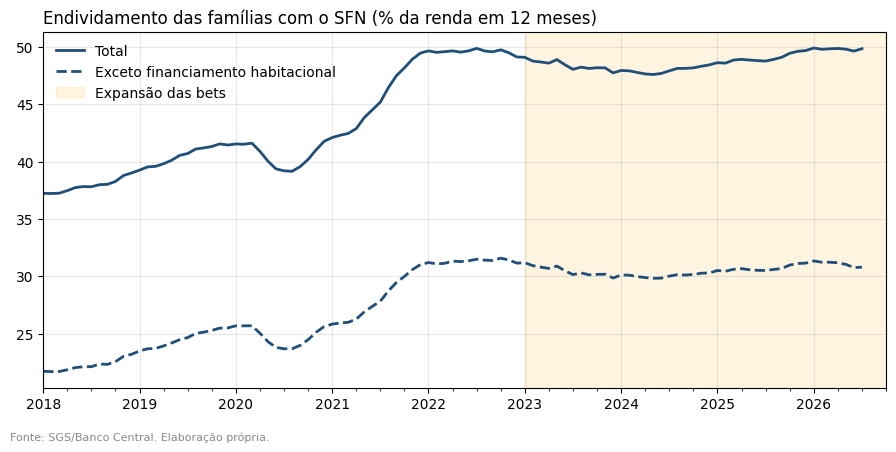

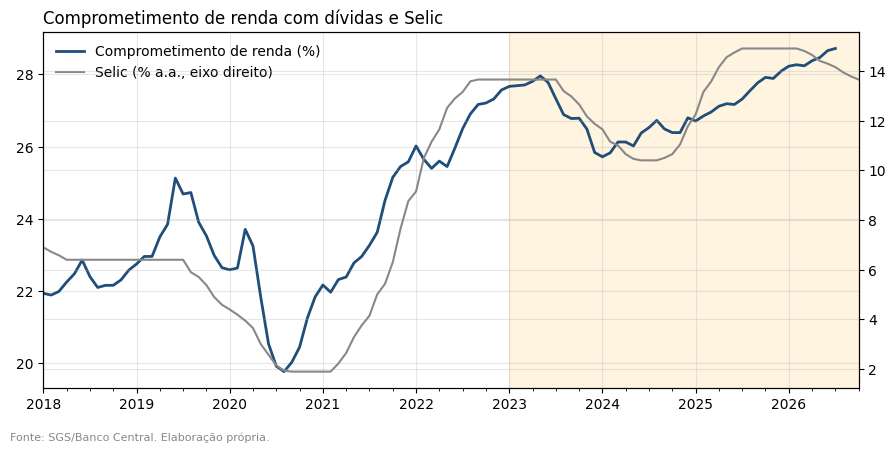

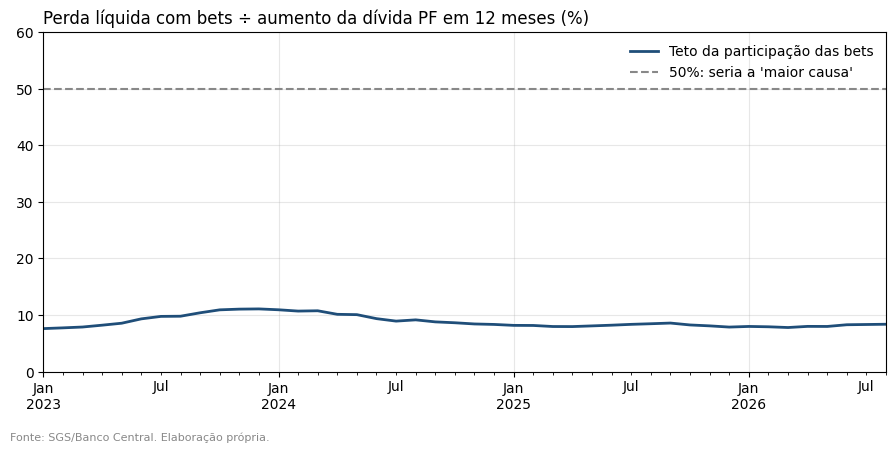

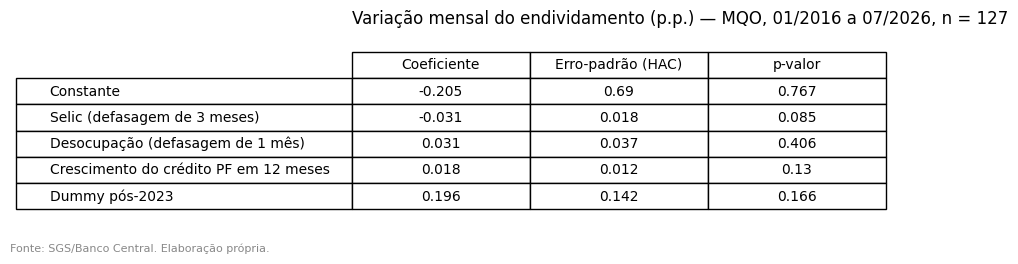

In [7]:
# Figuras para o artigo (salvas em PNG)
cor, cinza = "#1f4e79", "#888888"
fonte = "Fonte: SGS/Banco Central. Elaboração própria."

def finaliza(fig, nome):
    fig.text(0.01, 0.01, fonte, fontsize=8, color=cinza)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(nome, dpi=200); plt.show()

# Figura 1 — endividamento: a subida é anterior às bets
fig, ax = plt.subplots(figsize=(9, 4.5))
df["endiv"]["2018":].plot(ax=ax, color=cor, lw=2, label="Total")
df["endiv_exhab"]["2018":].plot(ax=ax, color=cor, lw=2, ls="--", label="Exceto financiamento habitacional")
ax.axvspan("2023-01-01", df.index.max(), color="orange", alpha=0.12, label="Expansão das bets")
ax.set_title("Endividamento das famílias com o SFN (% da renda em 12 meses)", loc="left")
ax.set_xlabel(""); ax.legend(frameon=False)
finaliza(fig, "fig1_endividamento.png")

# Figura 2 — comprometimento de renda e Selic
fig, ax = plt.subplots(figsize=(9, 4.5))
df["comprom"]["2018":].plot(ax=ax, color=cor, lw=2, label="Comprometimento de renda (%)")
ax2 = ax.twinx()
df["selic"]["2018":].plot(ax=ax2, color=cinza, lw=1.5, label="Selic (% a.a., eixo direito)")
ax.axvspan("2023-01-01", df.index.max(), color="orange", alpha=0.12)
ax.set_title("Comprometimento de renda com dívidas e Selic", loc="left"); ax.set_xlabel("")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left")
finaliza(fig, "fig2_comprometimento_selic.png")

# Figura 3 — teto da participação das bets no aumento da dívida
fig, ax = plt.subplots(figsize=(9, 4.5))
participacao["2023":].plot(ax=ax, color=cor, lw=2, label="Teto da participação das bets")
ax.axhline(50, color=cinza, ls="--", label="50%: seria a 'maior causa'")
ax.set_ylim(0, 60); ax.set_xlabel("")
ax.set_title("Perda líquida com bets ÷ aumento da dívida PF em 12 meses (%)", loc="left")
ax.legend(frameon=False)
finaliza(fig, "fig3_teto_bets.png")

# Tabela — regressão
tab = pd.DataFrame({"Coeficiente": res.params, "Erro-padrão (HAC)": res.bse, "p-valor": res.pvalues}).round(3)
tab.index = ["Constante", "Selic (defasagem de 3 meses)", "Desocupação (defasagem de 1 mês)",
             "Crescimento do crédito PF em 12 meses", "Dummy pós-2023"]
fig, ax = plt.subplots(figsize=(9, 2.6)); ax.axis("off")
t = ax.table(cellText=tab.values, rowLabels=tab.index, colLabels=tab.columns, loc="center", cellLoc="center")
t.auto_set_font_size(False); t.set_fontsize(10); t.scale(1, 1.6)
ax.set_title(f"Variação mensal do endividamento (p.p.) — MQO, {d.index[0]:%m/%Y} a {d.index[-1]:%m/%Y}, n = {int(res.nobs)}", loc="left")
finaliza(fig, "fig4_regressao.png")

## Conclusão

Resultados da execução (dados até jul–ago/2026):

- **Timing (gráfico da seção 2):** o endividamento subiu de ~39% para ~49,9% da renda entre meados de 2020 e o início de 2022 — **antes** da expansão das bets. De jan/2023 a jul/2026 ficou praticamente estável (+0,7 p.p.). A série sem financiamento habitacional tem o mesmo desenho.
- **Comprometimento de renda:** subiu de ~27,5% para ~28,7% após 2023, com estoque estável — efeito do custo da dívida, com a Selic de volta a 15%.
- **Teste 1:** a dívida PF cresceu R$ 442 bi em 12 meses. Mesmo que **toda** a perda líquida com bets (R$ 37 bi/ano) fosse financiada com crédito, explicaria no máximo **8,4%** do aumento; o teto oscilou entre 8% e 11% desde 2023.
- **Teste 3:** a dummy pós-2023 não é significativa (p = 0,17; efeito acumulado de 8,4 p.p., IC 95% de −3,5 a 20,4). Mesmo que fosse, ela mistura bets, consignado CLT e Desenrola.

**Resposta:** as bets não são a maior causa do endividamento das famílias. O grande aumento ocorreu em 2020–2022, antes delas; depois de 2023 o nível ficou estável e a pressão sobre o orçamento veio dos juros. As bets cabem, no máximo, em uma fração pequena do crescimento da dívida. Isso não contradiz os estudos com microdados (Insper), que mostram dano relevante ao apostador individual — sobretudo na baixa renda.

**Limitações:** dados agregados não identificam efeito causal; não há série pública de dívida PF por UF (o SGS só publica MEI por estado) para uma identificação regional; o teto do teste 1 depende do valor de `GGR_ANUAL`; o indicador de endividamento do BC usa renda disponível estimada e não separa as famílias que apostam das que não apostam.